# Monte Carlo Simulation

## Monte Carlo Approach

Monte Carlo methods are any process that consumes random numbers. These are part of computational algorithms which are based on random sampling to obtain numerical results. Monte Carlo methods are proved to be a very valuable and flexible computational tool in finance and is one of the most widely used methods for optimization and numerical integration problems.

These methods are widely used in high dimensional problems; pricing exotics and complex derivatives where closed form solutions are not directly available. Monte Carlo methods are not just adapted in pricing complex derivatives, It is also extensively used in estimating the portfolio risk such as Value-at-Risk and Expected Shortfall and used in the calculation of worst-case scenarios in stress testing. The downside to that is, it is very computational intensive and demanding.

### Monte Carlo Simulation

A method of estimating the value of an unknown quantity using the principles of inferential statistics.

We take the population and then we sample it by drawing a proper subset. And then we make an inference about the population based upon some set of statistics we do on the sample.

And, the key fact that makes them work, that if we choose the sample at random, the sample will tend to exhibit the same properties as the population from which it is drawn.

### Option Pricing Techniques

As with other option pricing techniques Monte Carlo methods are used to price options using what is essentially a three step process.

 **Step 1**: Simulate potential price paths of the underlying asset. <br>
**Step 2**: Calculate the option payoff for each of these price paths. <br>
**Step 3**: Average the payoff and discount back to today to determine the option price.

Next, we will simulate the asset price at maturity $S_T$. Following Black-Scholes-Merton where the underlying follows under risk neutrality, a geometric Brownian motion with a stochastic differential equation (SDE) is given as

$$ dS_t = rS_tdt + \sigma S_tdX_t$$

where $S_t$ is the price of the underlying at time t, σ is constant volatility, r is the constant risk-free interest rate and 
X is the brownian motion.

Applying Euler discretization of SDE, we get

$$ S_{t+ \delta{t}} = S_t * (1 + r \delta{t} + \sigma \sqrt{\delta{t}} \phi_t) $$

It is often more convenient to express in time stepping form
$$ S_{t+ \delta{t}} = S_t * e^{( r - \frac{1}{2} \sigma^2)\delta{t} + \sigma \sqrt{\delta{t}} \phi_t)} $$


The variable $\phi_t$ is a standard normally distributed random variable, 0 < $\delta{t}$ < T, time interval. It also holds 0 < t ≤ T with T the final time horizon.

### Generate Price Paths

Simulating price paths plays an important role in the valuation of derivatives and it is always prudent to create a separate path function.

#### Import Libraries

In [11]:
# data manipuation
import pandas as pd
import numpy as np

# to reload another python script 
from importlib import reload

# data visualization
import matplotlib as mpl
import matplotlib.pyplot as plt

import seaborn as sns

import cufflinks as cf                                                        # new package - cufflinks
cf.set_config_file(offline=True, theme='pearl',dimensions=((1000,600)))       # cf.set_config() -- (w,h)

import plotly.express as px
px.defaults.width, px.defaults.height = 1000,600

# statistical analysis & optimizatio
import scipy.stats as scs
import scipy.optimize as sco

# scikit learn(sklearn) package is used primarily for machine learning
import sklearn

# Ignore warnings - optional
import warnings
warnings.filterwarnings('ignore')

# data retrival
import yfinance as yf

# float display
pd.options.display.float_format = '{:0.4f}'.format

# operating system
import os

# Image package
from PIL import Image

# tabke formation
from tabulate import tabulate

# datetime handling
from datetime import datetime

path_dir = 'C:/Admin/CQF Course/Python Labs/Monte Carlo Simulation'

### User Defined Function

In [2]:
def simulate_path(s0,mu,sigma,horizon,timesteps,n_sims):
    
    # set the random seed for reproducibility
    np.random.seed(42)
    
    # parameters
    S0 = s0
    r = mu
    T = horizon
    t = timesteps
    n = n_sims
    
    dt = T/t
    
    # Stock Price matrix
    S = np.zeros([t,n])
    S[0] = S0
    
    # create Stock Price matrix
    for i in range(1,t):
        S[i] = S[i-1]*(1 + r *dt + sigma*np.sqrt(dt)*np.random.standard_normal(n) )                  # np.random.standard_normal
        #S[i] = S[i-1]*np.exp((r-0.5*sigma**2)*dt +sigma*np.sqrt(dt)*np.random.standard_normal())    
    
    return S
    

### Histogram of Psuedo Random Numbers

In [3]:
# Assign simulated price path to dataframe for analysis and plotting
price_path = pd.DataFrame(simulate_path(100,0.05,0.2,1,252,100000))

### Histogram of Simulated Paths

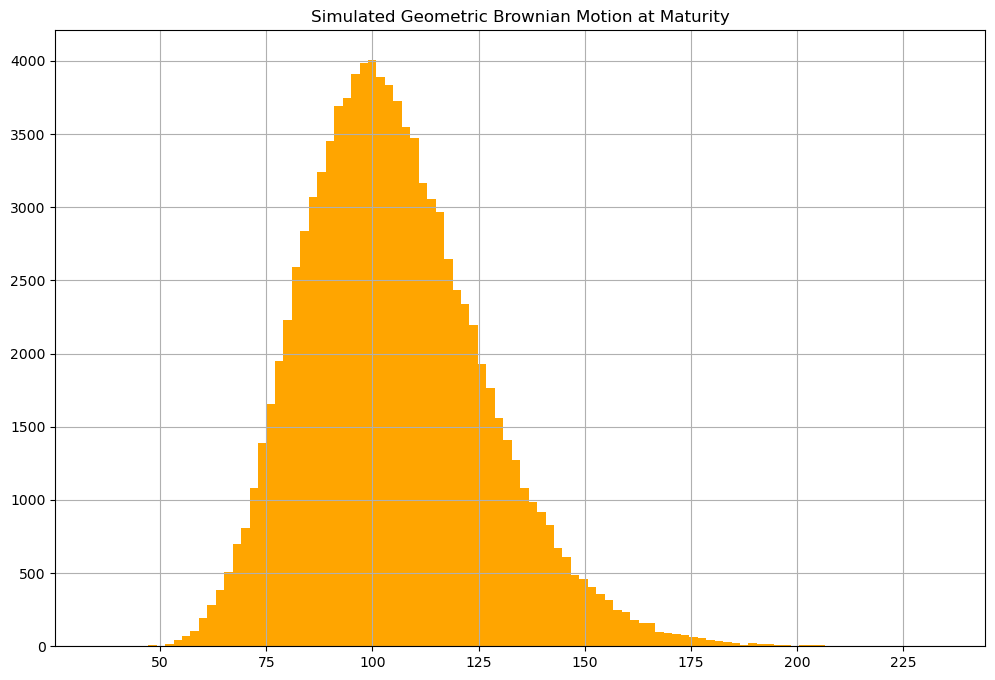

In [5]:
plt.figure(figsize =(12,8)) 
price_path.iloc[-1,].hist(bins=100,color= 'orange')
plt.title('Simulated Geometric Brownian Motion at Maturity');
plt.show()

### Visualization of Simulated Paths

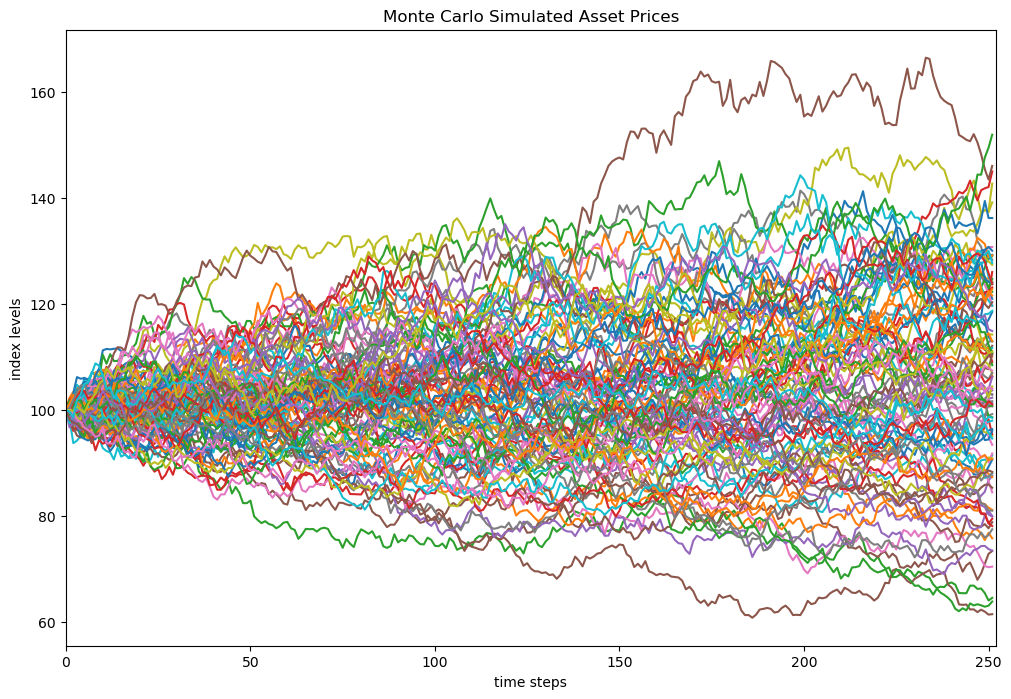

In [6]:
price_path.iloc[:,:100].plot(figsize =(12,8), legend = False)
plt.title('Monte Carlo Simulated Asset Prices')
plt.xlabel('time steps')
plt.xlim(0,252)
plt.ylabel('index levels')
plt.show()

## Risk-Neutral Valuation

A call option gives the holder of the option the right to buy the asset at a pre-defined price. A call buyer makes money if the price of the asset at maturity, denoted by $S_T$, is above the strike price K, otherwise it's worth nothing.

$$ C_T = max(S_T - K,0)$$
The price of an option using a Monte Carlo simulation is the expected value of its future payoff. So at any date before maturity, denoted by t, the option's value is the present value of the expectation of its payoff at maturity, T

$$ C_t = PV(E[max(S_T -K,0)])$$

Under the risk-neutral framework, we assume the asset is going to earn, on average, the risk-free interest rate. Hence, the option value at time t would simply be the discounted value of the expected payoff.

$$ C_t = e^{-r(T-t)}(E[max(S_T -K,0)])$$

### European Option

To price an option, we generate many possible price paths that the asset might take at maturity and then calculate option payoffs for each of those generated prices, average them to get the expected payoff and then discount it at risk free to arrive at the final value.

Given that Monte Carlo algorithms are computationaly heavy, it is necessary to implement efficiently. We'll use vectorization with NumPy for effective algorithm as NumPy syntax are more compact and are faster.

#### Option Value

In [7]:
# Call the simulation function
S = simulate_path(100,0.05,0.2,1,252,100000)

# define parameter
K = 100; r=0.05; T=1                                           # semi-colon used to assign values for each attribute
 
# Calculate the discounted value of the expeced payoff
C0 = np.exp(-r*T)*np.mean(np.maximum(S[-1]-K,0))
P0 = np.exp(-r*T)*np.mean(np.maximum(K-S[-1],0))

print('call option value is {:4f}'.format(C0))
print('put option value is {:4f}'.format(P0))

call option value is 10.399795
put option value is 5.567869


#### Option Payoff at Maturity

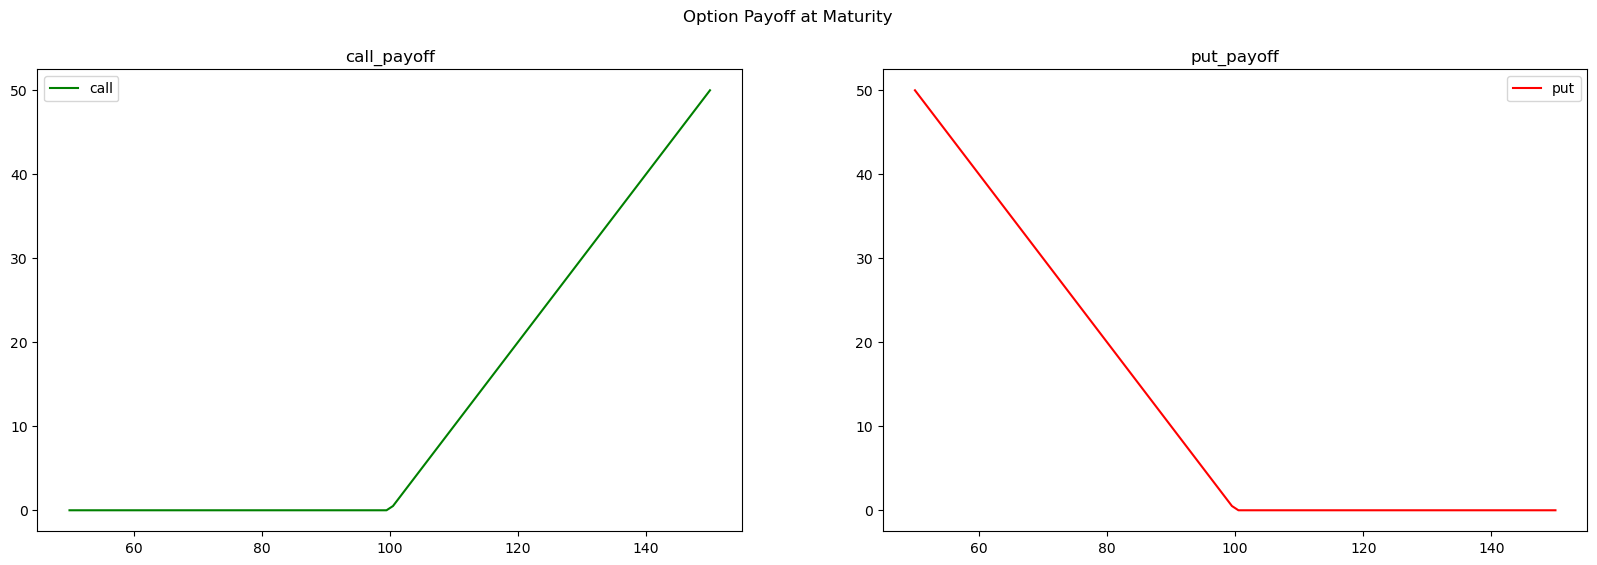

In [8]:
# range of spot prices 
S_T = np.linspace(50,150,100)

# visualize call and put price for range of spot prices
fig,ax = plt.subplots(ncols=2,figsize =(20,6))                

title, payoff, color, label = ['call_payoff','put_payoff'], [np.maximum(S_T - K,0),np.maximum(K- S_T,0)], ['green','red'],['call','put']

for i in range(2):
    ax[i].plot(S_T, payoff[i], label = label[i], color = color[i])
    ax[i].set_title(title[i])
    ax[i].legend()
    
fig.suptitle('Option Payoff at Maturity');

### Asian Call Option

An Asian option is an option where the payoff depends on the average price of the underlying asset over a certain period of time. Averaging can be either be Arithmetic or Geometric. There are two types of Asian options: fixed strike, where averaging price is used in place of underlying price; and fixed price, where averaging price is used in place of strike.

We'll now price a fixed strike arthmetic average option using Monte Carlo simulation.
The payoff of the options is given by

$$ C_T = max(0,1/T  \sum_{i=1}^{T} S_i - K) $$
$$ C_T = max(0,S_{avg} - K) $$

where $S_{avg}$ is the average price of the underlying asset over the life of the option. To price an option using a Monte Carlo simulation we use a risk-neutral valuation, where the fair value for a derivative is the expected value of its future payoff. So at any date before maturity, denoted by t, the option's value is the present value of the expectation of its payoff at maturity T

$$ C_t = PV(E[max(S_{avg} -K,0)])$$
Under the risk-neutral framework, we assume the asset is going to earn, on average, the risk-free interest rate. Hence, the option value at time t would simply be the discounted value of the expected payoff.

$$ C_t = e^{-r(T-t)}(E[max(S_{avg} -K,0)])$$

In [9]:
# Call the simulation function
S = simulate_path(100,0.05,0.2,1,252,100000)

# define parameter
K = 100; r=0.05; T=1                                           
 
# Calculate the discounted value of the expeced payoff
C0 = np.exp(-r*T)*np.mean(np.maximum(np.mean(S,axis=0)-K,0))
P0 = np.exp(-r*T)*np.mean(np.maximum(K-np.mean(S,axis=0),0))

print('call option value is {:4f}'.format(C0))
print('put option value is {:4f}'.format(P0))

call option value is 5.740119
put option value is 3.340469


### Up/down  and in/out Barrier Call/put Option

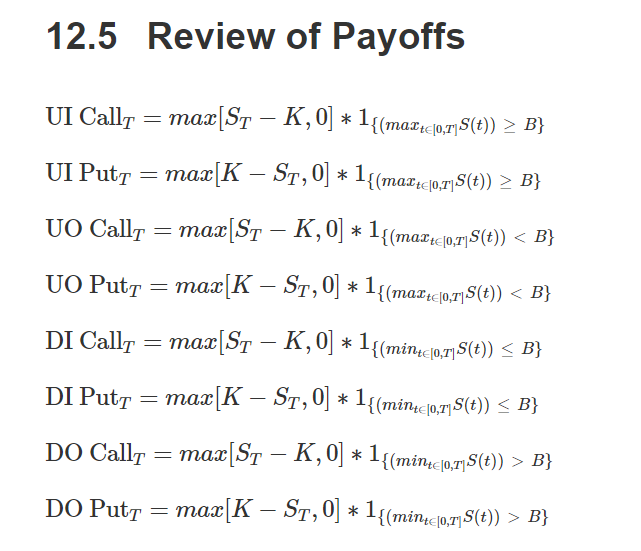

In [12]:
Image.open(os.path.join(path_dir,'MC_1.png'))

**these are important, consider NIFTY at 19k, you know next 1 year, it wont breach 21K, means max 10% upside... so why we are payying premium for unlimited upside, we can reduce it using up and out call option**

Barrier Options are path dependent exotic options whose payoff depends on whether the price of the underlying asset crosses a pre specified level (called the ‘barrier’) before the expiration. The four main types of barrier options are:

- Up-and-out
- Down-and-out
- Up-and-in
- Down-and-in

Refer Paul Wilmott on Quantitative Finance Chapter 23 — Barrier Options and Chapter 77 — Finite Difference Methods for One-factor Models for further details on barriers.

Next, we will price a Up-Out-Call barrier with and without rebate using Monte Carlo simulation. Barrier options can be priced using analytical solutions if we assume continuous monitoring of the barrier. However, in reality many barrier contracts specify discrete monitoring.

In a paper titled A Continuity Correction for Discrete Barrier Option, Mark Broadie, Paul Glasserman and Steven Kou have shown us that the discrete barrier options can be priced using continuous barrier formulas by applying a simple continuity correction to the barrier. The correction shifts the barrier away from the underlying by a factor of

$$ exp^{\beta \sigma \sqrt{\Delta t}} $$

where β ≈ 0.5826and σis the underlying volatility, and Δt is the time between monitoring instants. We will apply this continuity correction in our pricing method as well.

In [14]:
S = simulate_path(100,0.05,0.2,1,252,100000)

# Define parameters
K=100 ; B=150 ; r = 0.05 ; sigma = 0.2 ; T=1; t = 252 ; dt = T/t; n = 100000 ; rebate = 30 ; value =0

# Barrier shift - continuity correction for discrete monitoring
B_shift = B*np.exp(0.5826*sigma*np.sqrt(dt))

# Calculate the discounted value of the expeced payoff
for i in range(n):
    value = value + np.max(S[-1,i]-K,0) if np.max(S[:,i])< B_shift else value + rebate

C0 = np.exp(-r*T)*value/n
print('call option value is {:4f}'.format(C0))

call option value is 3.752840


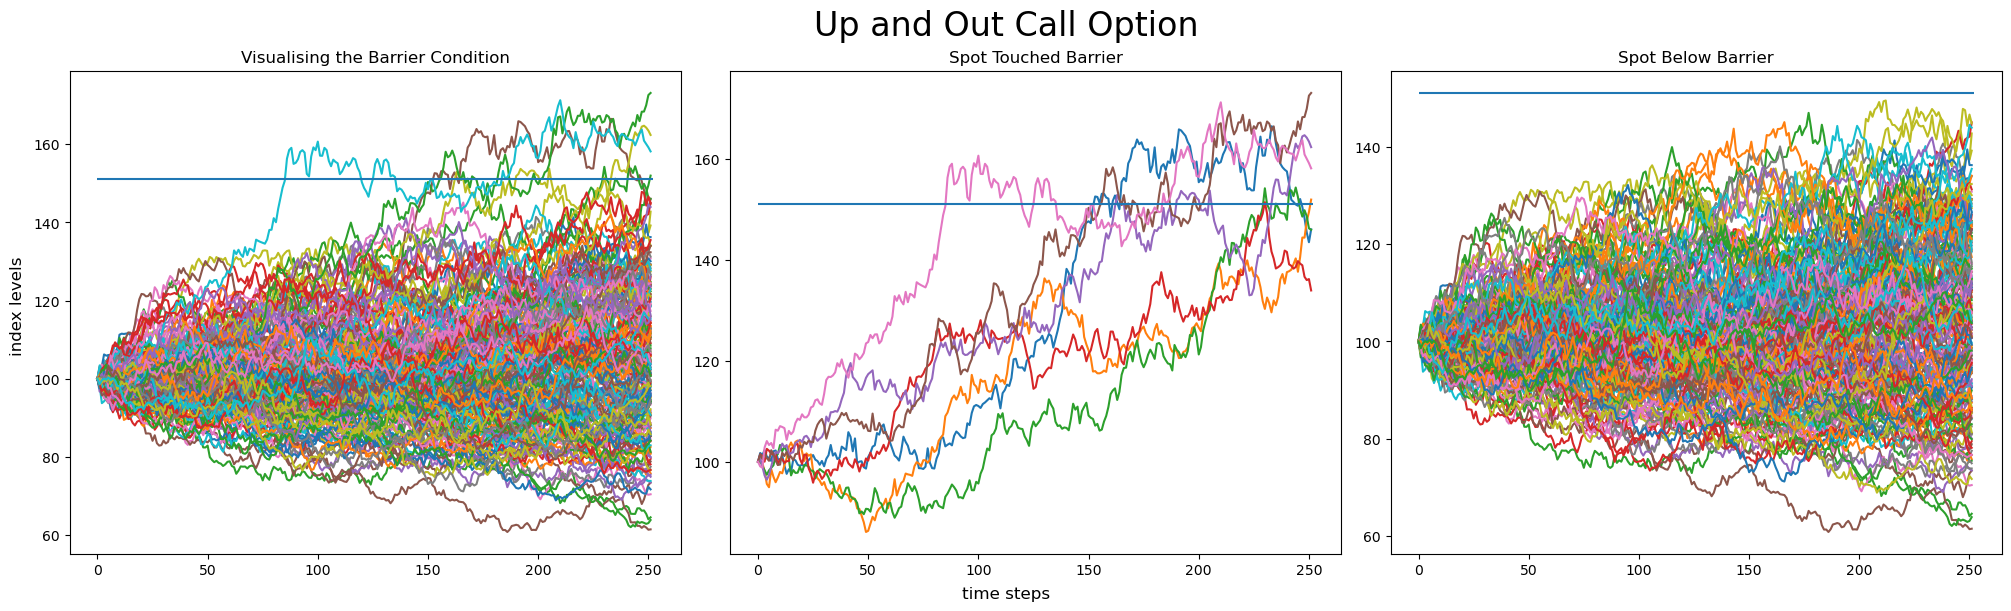

In [15]:
figure,axes = plt.subplots(ncols=3,figsize =(20,6),constrained_layout=True)                

title = ['Visualising the Barrier Condition', 'Spot Touched Barrier', 'Spot Below Barrier']

axes[0].plot(S[:,:200])

for i in range(200):
    axes[1].plot(S[:,i])  if np.max(S[:,i]) > B_shift else axes[2].plot(S[:,i])

for i in range(3):   
    axes[i].set_title(title[i])
    axes[i].hlines(B_shift,0,252)

figure.suptitle('Up and Out Call Option',fontsize =24)
figure.supxlabel('time steps')
figure.supylabel('index levels')

plt.show()

## References 

- Paul Glasserman (2004), Monte Carlo Methods in Financial Engineering
- Paul Wilmott (2007), Paul Wilmott introduces Quantitative Finance
- [Python Resources](https://github.com/kannansingaravelu/PythonResources)
- [Understanding Options](https://www.cmegroup.com/education/articles-and-reports/implied-volatility.html)